# Advanced CAPTCHA Studio

**CAPTCHA** = *Completely Automated Public Turing test to tell Computers and Humans Apart*.

The basic version of this project (`01_Basic_CAPTCHA_original.ipynb`) used the `captcha`
library to write one fixed image and one audio file. This notebook upgrades it to a
complete system:

| Feature | Basic | Advanced |
|---|---|---|
| Image generation | library black box | own engine (Pillow + NumPy): rotation, sine-wave warp, Bezier curves, noise |
| Difficulty | one | Easy / Medium / Hard presets + 4 colour themes |
| Challenge text | hard-coded | cryptographically secure random text, no look-alike characters |
| Challenge types | text | text **and** math (`7 + 5 = ?`) |
| Verification | none | HMAC-SHA256 hashed answers, expiry, attempt limit, single-use, rate limit |
| Accessibility | audio file | audio CAPTCHA served for numeric challenges |
| Interface | notebook | notebook + CLI + Flask web app + unit tests |

In [1]:
import sys
sys.path.insert(0, "..")          # make the captcha_studio package importable from /notebooks

from captcha_studio import (ImageCaptchaGenerator, CaptchaManager, Difficulty, VerifyResult,
                            random_text, math_challenge, make_grid, THEMES)
print("CAPTCHA Studio ready")

CAPTCHA Studio ready


## 1. Secure challenge text

`random.choice` is predictable (Mersenne Twister). We use `secrets.choice`, which is
cryptographically secure. Confusing characters such as `0/O`, `1/l/I`, `5/S` are removed
so humans don't fail for the wrong reason.

In [2]:
for charset in ["digits", "upper_alnum", "alnum", "complex"]:
    print(f"{charset:12s} ->", [random_text(6, charset) for _ in range(4)])

m = math_challenge()
print("\nmath challenge:", m.question, "  answer:", m.answer)

digits       -> ['165769', '181124', '012300', '242176']
upper_alnum  -> ['DXXRLW', 'Q3F9LG', 'JVGLQE', 'WRNFVT']
alnum        -> ['fwTdnr', 'Hm3Pwe', 'P6hqyF', '7q7PGP']
complex      -> ['9Ada9M', '3mdXq4', 'gdhYze', 'Vkwzxq']

math challenge: 7 + 10 = ?   answer: 17


## 2. The image pipeline

```
gradient background -> background noise / grid
-> each character drawn on its own layer (random font, size, rotation, colour)
-> characters pasted with overlap + vertical jitter
-> sine-wave warp (non-linear distortion)
-> Bezier interference curves -> speckle noise -> blur
```

Below: the same project text from the original notebook, `9Pyth0n4d@tA6`, rendered at
the three difficulty levels.

EASY
MEDIUM
HARD


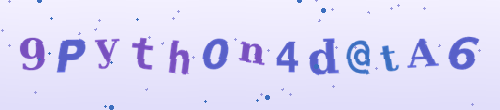

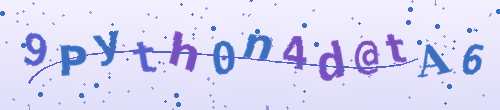

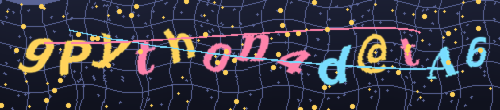

In [3]:
text = "9Pyth0n4d@tA6"
for level in Difficulty:
    print(level.value.upper())
    display(ImageCaptchaGenerator(level, width=500, height=110).generate(text))

## 3. The four sample CAPTCHAs

Easy (text), Medium (text), Hard (text with symbols) and Math - each with a different theme.

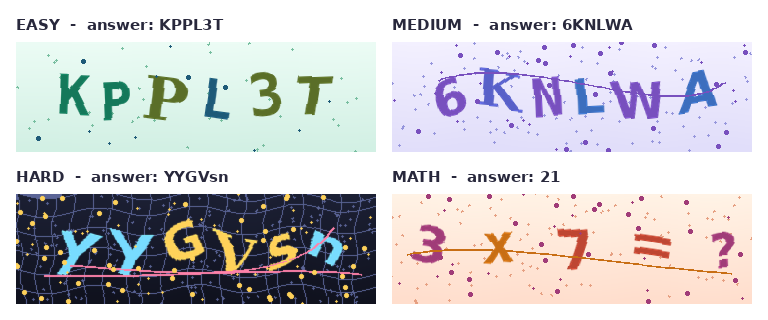

In [4]:
mc = math_challenge()
samples = [
    ("EASY",   ImageCaptchaGenerator("easy", theme="mint"),               random_text(6, "upper_alnum")),
    ("MEDIUM", ImageCaptchaGenerator("medium"),                           random_text(6, "alnum")),
    ("HARD",   ImageCaptchaGenerator("hard"),                             random_text(6, "complex")),
    ("MATH",   ImageCaptchaGenerator("medium", theme="sunset", rotation=10), mc.question),
]
images, labels = [], []
for name, gen, txt in samples:
    images.append(gen.generate(txt))
    answer = mc.answer if name == "MATH" else txt
    labels.append(f"{name}  -  answer: {answer}")

display(make_grid(images, labels, cols=2))

## 4. Every parameter is tunable

`ImageCaptchaGenerator(difficulty, **overrides)` accepts any field of `Style`
(`rotation`, `overlap`, `wave_amplitude`, `curves`, `dots`, `blur`, `theme`, ...).

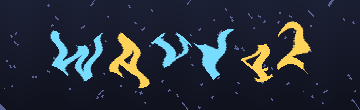

In [5]:
custom = ImageCaptchaGenerator("medium", theme="night", rotation=0, wave_amplitude=8,
                               wave_period=60, curves=0, dots=0)
display(custom.generate("WAVY42"))

## 5. Verification system (`CaptchaManager`)

A CAPTCHA is only useful if the server can check the answer safely:

* the answer is stored only as an **HMAC-SHA256** digest (a database leak reveals nothing)
* comparison uses `hmac.compare_digest` (constant time - no timing attack)
* each challenge **expires** (default 120 s) and is **single-use**
* only **3 attempts** per challenge, plus a per-client **rate limit**

In [6]:
mgr = CaptchaManager(ttl_seconds=120, max_attempts=3)
ch = mgr.issue("medium", mode="math")
print("challenge id :", ch.id)

# peek at the stored record: only a hash, never the answer
print("stored digest:", mgr._store[ch.id].digest.hex()[:32], "...")

print("attempt 1 'abc'  ->", mgr.verify(ch.id, "abc").value, "| attempts left:", mgr.attempts_left(ch.id))
print("attempt 2 '-1'   ->", mgr.verify(ch.id, "-1").value,  "| attempts left:", mgr.attempts_left(ch.id))
print("attempt 3 '9999' ->", mgr.verify(ch.id, "9999").value)
print("after lock-out   ->", mgr.verify(ch.id, ch.audio_digits).value)
print("\nstats:", mgr.stats)

challenge id : WVo0yzWU-VDhD1q_MRQtCw
stored digest: 852ee64cb222329f2f7aa11dde177d81 ...
attempt 1 'abc'  -> wrong | attempts left: 2
attempt 2 '-1'   -> wrong | attempts left: 1
attempt 3 '9999' -> too_many_attempts
after lock-out   -> not_found

stats: {'issued': 1, 'passed': 0, 'failed': 3, 'expired': 0}


## 6. Audio CAPTCHA (accessibility)

Visually-impaired users need an alternative. Numeric challenges (e.g. math answers) can be
spoken using the `captcha` library's voice files (`pip install captcha`).

In [ ]:
from captcha_studio import AudioCaptchaGenerator, audio_available
from IPython.display import Audio

if audio_available():
    AudioCaptchaGenerator().save("978", "../output/audio_978.wav")
    display(Audio("../output/audio_978.wav"))
else:
    print("pip install captcha   to enable audio")
    display(Audio("../samples/audio_captcha_978.wav"))   # pre-generated sample

## 7. Run it as a website

```bash
python app.py          # open http://127.0.0.1:5000
```

The page lets you pick difficulty and type, refresh the CAPTCHA, listen to it, and shows a
live expiry countdown and attempts left.

## 8. Ideas to extend

* Train a small CNN on generated images to **measure** how robust each difficulty level is
  against machine solving (generate thousands of labelled images with `make_samples.py`).
* Store challenges in Redis instead of memory so several servers can share them.
* Add an image-selection CAPTCHA ("click all the squares with...").